# 08 · What does CoreWeave's survival depend on? Customers, rent, and the price of an old GPU

**The question.** 06 showed CoreWeave can't pay for replacing its GPUs from today's cash flow. This notebook asks what has to go right for its lenders to be repaid:
- who owes CoreWeave the money;
- whether those customers stay as long as CoreWeave's rent bills do;
- what price an old GPU has to rent for after its first contract ends.

The last section compares CoreWeave with Nebius, a neocloud running the same business with a different mix of funding.

**Short answer** (Q2 2026 filings; CoreWeave's Q3 10-Q is due ~Nov 10):
1. **Microsoft, Meta, OpenAI, Anthropic and Jane Street are the contracts that matter, and every AI-model customer among them is also building or buying compute elsewhere** (§1, `08_customers.png`). Meta's contracts (up to ~$35B) are with an AA- company. OpenAI's (~$22B) and Jane Street's ($6B) are with private, unrated companies. The other ~$40B of the backlog is Microsoft, Anthropic and others, with no amounts disclosed.
2. **The rent outlasts the customers** (§2, `08_rent_vs_contracts.png`). Customer contracts average ~5 years, and 80% of today's backlog is used up by mid-2030. CoreWeave has ~$65B of data-center rent committed, which runs to the late 2030s. That's the restaurant chain: long leases, short customers.
3. **The threshold is a price, not a level of AI spending** (§3, `08_renewal_breakeven.png`). On CoreWeave's average economics, a 5-year contract leaves lenders ~1% short of being repaid. Lenders come out whole only if, once the contract ends, the GPUs earn at least ~46% of the old contract's revenue for their last year. That's the same as old-GPU prices falling no faster than ~14% a year. H100 rents fell ~19% a year. *(Revised in 10 §1: H100 rents bottomed in early 2026 and rose; from Jan 2024 to Nov 2026 they are roughly flat, −5% to +10% a year depending on the measure.)* **So a world with booming AI demand, but rental prices falling the way H100s' did, is enough to leave lenders short.** Shareholders need much more: ~75–95% of the old price and GPUs lasting 7+ years.
4. **The best contract is already spoken for** (§3). The Meta contract behind the A3-rated secured loan pays back its loan with ~$57 to spare per $100 of equipment, even with no renewal. The unsecured bonds are repaid from everything else, which looks like the company average.
5. **A paid-off GPU is worth far more to SpaceX than to CoreWeave** (§3b, `08_paid_off_gpu.png`). An old H100 earns the same cash anywhere. SpaceX owns its data centers and keeps it, ~$7–69 per $100 of the GPU's first-year revenue over years 6–10. CoreWeave owes rent of ~20% of revenue on the space whether the GPU runs or not, so the old GPU only shrinks a loss.
6. **Nebius funds the same business mostly with shareholders' money** (§4, `08_funding_mix.png`). Lenders paid for ~34% of what Nebius has raised, against ~71% at CoreWeave. Nebius holds cash about equal to its debt, and pays 1.25–2.6% on convertible notes, against CoreWeave's 9–9.75% on unsecured bonds. Its convertible holders accept the lower coupon because they also share in the upside if the stock rises.
7. **Selling stock is a real backstop for the near maturities, not for the 2031–32 notes** (§5, `08_equity_backstop.png`). At $48.73 (Nov 10), CoreWeave could cover the ~$9.5B due by end-2028 beyond its cash by selling ~26% of the company, and it set up a 35M-share stock-sale program in Sep 2026 citing debt repayment. But the stock falls in the same worlds where GPU prices fall: at −75% (options: ~37% odds by Jan 2029), the same raise means selling ~59%. Only Nvidia's $6.3B capacity order (press) pays out because demand is weak.

| § | Question | Chart |
|---|---|---|
| 1 | Who owes CoreWeave the money, and do they have alternatives? | `08_customers.png` |
| 2 | Do the customers stay as long as the rent? | `08_rent_vs_contracts.png` |
| 3 | After a contract ends, what must an old GPU earn for lenders to be repaid? | `08_renewal_breakeven.png` |
| 3b | What is a paid-off GPU worth: CoreWeave vs. SpaceX? | `08_paid_off_gpu.png` |
| 4 | How does Nebius fund the same business? | `08_funding_mix.png` |
| 5 | Could CoreWeave sell stock to repay its bonds? | `08_equity_backstop.png` |

**Inputs:**
- `data/neocloud_inputs.csv`: every number hand-read from CoreWeave's Q2 10-Q and earnings release, the DDTL 4.0 lender deck, and Nebius's Q2 6-K, each with a source URL. Model assumptions are marked `assumption`.
- `data/neocloud_customers.csv`: CoreWeave's disclosed customer contracts, each customer's credit, and what else it builds or buys.
- `data/crash_odds.csv` (06 §8, option-implied odds of large falls), `data/fundamentals.csv` (06), `data/merton_inputs.csv` (05).
- `data/fleet.csv` (CoreWeave's equipment cost), `bonds.csv` (coupons), `issuers.csv` (CoreWeave debt and cash).
- Filings are cached in `data/edgar/` (`crwv_10q_2026q2`, `crwv_10k_2025`, `nbis_6k_2026-08-12_*`).

**Outputs:** the six charts above. `data/equity_backstop.csv` (§5's dilution table, read by `research.ipynb`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from common import INK, INK2, MUTED, AXIS, GRID, SURFACE, BOND, RAMP, EQUITY, source_note

plt.rcParams['text.parse_math'] = False   # chart labels are full of dollar signs
CHARTS = Path('charts')
INP = pd.read_csv('data/neocloud_inputs.csv').set_index('item')
v = lambda k: float(INP.loc[k, 'value'])
CUST = pd.read_csv('data/neocloud_customers.csv')
bonds = pd.read_csv('bonds.csv').set_index('bond_id')
issuers = pd.read_csv('issuers.csv').set_index('issuer')
fleet = pd.read_csv('data/fleet.csv')

## 1 · Who owes CoreWeave the money, and do they have alternatives?

**Why ask.** CoreWeave's lenders are really lending against its customer contracts (02 and 06). 98% of its revenue comes from multi-year "take-or-pay" contracts: the customer pays for the capacity whether it uses it or not. So the first question is who those customers are, whether they're good for the money, and whether they need CoreWeave at all.

**Method.** CoreWeave names its big contracts in its 10-K and 10-Q risk factors, as "up to" amounts. These are ceilings over the whole contract, not what's left to pay, so they overstate what each customer still owes. We set them against the $103.7B backlog at Jun 30. Credit is each customer's own rating where it has one. "Other compute" is what each customer is building or buying besides CoreWeave, from company announcements and press (sources in the CSV).

In [2]:
crwv = CUST[CUST.provider == 'CoreWeave']
cust = crwv.groupby('customer', sort=False).agg(**{'contracts, up to ($bn)': ('contract_bn', lambda s: s.sum(min_count=1)),
                                                 'signed': ('signed', ', '.join), 'credit': ('credit', 'first'),
                                                 'other compute': ('other_compute', 'first')})
RPO = v('crwv_rpo')
named = cust['contracts, up to ($bn)'].sum()
print(f'Named ceilings ${named:.1f}B of ${RPO:.1f}B backlog; the rest (${RPO - named:.1f}B) is undisclosed. '
      f'Top 3 customers: {v("crwv_top3_share_q2"):.0%} of Q2 revenue.')
cust

Named ceilings $63.6B of $103.7B backlog; the rest ($40.1B) is undisclosed. Top 3 customers: 72% of Q2 revenue.


,"contracts, up to ($bn)",signed,credit,other compute
customer,,,,
Microsoft,NaN,2023-2025,AAA/Aaa (investment grade),Own Azure data centers; Maia 200 in-house chip...
Meta,35.2,"2025-09, 2026-03",AA-/Aa3 (investment grade),"Own campuses: Hyperion (LA, via Beignet) and E..."
OpenAI,22.4,"2025-03, 2025-05, 2025-09",private (no public rating),Stargate with Oracle/SoftBank; Broadcom custom...
Jane Street,6.0,2026-04,private (no public rating),Trading firm; not a model builder
Anthropic,NaN,2026-04,private (no public rating),"Google TPUs (up to 1M chips, >1 GW in 2026); A..."


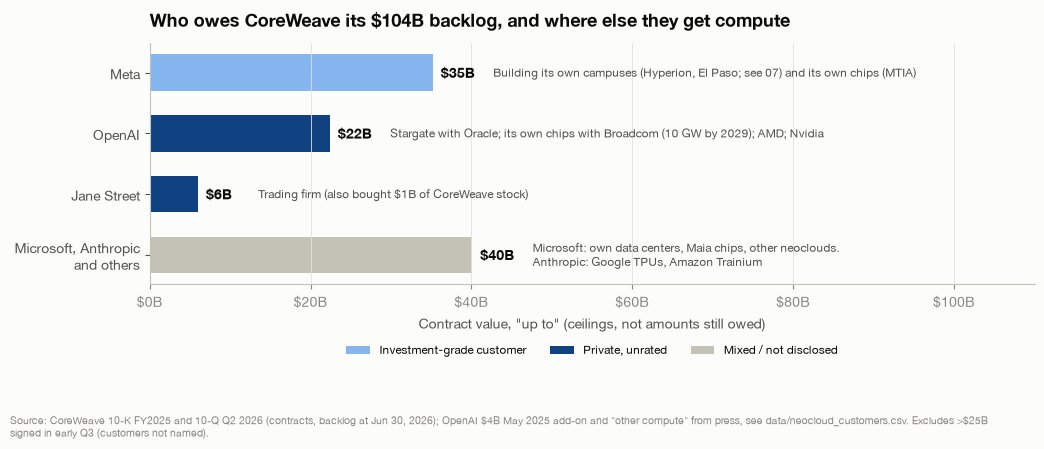

In [3]:
rows = [('Meta', cust.loc['Meta', 'contracts, up to ($bn)'], 'ig', 'Building its own campuses (Hyperion, El Paso; see 07) and its own chips (MTIA)'),
        ('OpenAI', cust.loc['OpenAI', 'contracts, up to ($bn)'], 'private', 'Stargate with Oracle; its own chips with Broadcom (10 GW by 2029); AMD; Nvidia'),
        ('Jane Street', cust.loc['Jane Street', 'contracts, up to ($bn)'], 'private', 'Trading firm (also bought $1B of CoreWeave stock)'),
        ('Microsoft, Anthropic\nand others', RPO - named, 'mixed', 'Microsoft: own data centers, Maia chips, other neoclouds.\nAnthropic: Google TPUs, Amazon Trainium')]
col = {'ig': RAMP[0], 'private': RAMP[2], 'mixed': AXIS}
fig, ax = plt.subplots(figsize=(10.5, 4.2))
for i, (name, amt, kind, alt) in enumerate(rows):
    ax.barh(i, amt, color=col[kind], height=0.6)
    ax.text(amt + 1, i, f'${amt:,.0f}B', va='center', fontsize=10, fontweight='bold', color=INK)
    ax.text(amt + 7.5, i, alt, va='center', fontsize=8.5, color=INK2)
ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlim(0, 110); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}B'))
for kind, lab in [('ig', 'Investment-grade customer'), ('private', 'Private, unrated'), ('mixed', 'Mixed / not disclosed')]:
    ax.barh(np.nan, 0, color=col[kind], label=lab)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8.5)
ax.set_title(f"Who owes CoreWeave its ${RPO:,.0f}B backlog, and where else they get compute", pad=12)
ax.set_xlabel('Contract value, "up to" (ceilings, not amounts still owed)')
source_note(fig, 'Source: CoreWeave 10-K FY2025 and 10-Q Q2 2026 (contracts, backlog at Jun 30, 2026); OpenAI $4B May 2025 add-on and "other compute" from press, see data/neocloud_customers.csv. '
                 'Excludes >$25B signed in early Q3 (customers not named).')
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(CHARTS / '08_customers.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/08_customers.png`, above):
- **One investment-grade customer is disclosed by amount:** Meta, up to ~$35B across two contracts. Microsoft (AAA) was 67% of 2025 revenue, but CoreWeave doesn't disclose what it still owes.
- **~$28B of the named ceilings are with private, unrated companies** (OpenAI ~$22B, Jane Street $6B). CoreWeave itself flags them as a credit risk ("private companies that may have increased risk of insolvency").
- **Every AI-model customer is also building or buying elsewhere, and often not on Nvidia GPUs:**
  - Meta is building its own campuses (07);
  - OpenAI has Stargate and its own Broadcom chips;
  - Anthropic runs mostly on Google TPUs and Amazon Trainium;
  - Microsoft has its own chips and other neoclouds, including Nebius (§4).
- **So these customers rent from CoreWeave because they can't build fast enough themselves, not because they have nowhere else to go.** That holds up while compute is short. When their own capacity catches up, CoreWeave is the first supplier they can cut.
- Concentration is falling: the top customer was 71% of revenue a year ago and 36% in Q2. The top three are still 72%.

**Next:** take-or-pay protects CoreWeave while a contract runs. What happens when it ends?

## 2 · Do the customers stay as long as the rent?

**Why ask.** A restaurant chain goes bust when its leases outlast its customers: it still owes rent on locations nobody walks into. CoreWeave mostly rents its data centers rather than owning them. If its leases run longer than its customer contracts, it carries a fixed bill into years when no customer is contracted to pay.

**Method.**
- **Contracted revenue by year:** the 10-Q says when the $103.7B backlog turns into revenue: 41% in the first 24 months (to Jun 2028), 39% in months 25–48 (to Jun 2030), 20% in months 49–78 (to Dec 2032). We spread each bucket evenly over its months.
- **The >$25B signed in early Q3** has no disclosed timing. We assume it follows the same pattern (shown separately).
- **Rent:** the 10-Q's operating-lease payment schedule for leases already running. We spread the "thereafter" amount evenly to the 12-year average remaining term, i.e. ~2038.
- **Signed leases that haven't started:** a further $35.5B (terms 7–16 years, starting 2026–29). We assume they start in 2028 and run 11.5 years, evenly.
- **Not counted:** one more site whose rent is capped at $14.7B but uncertain.

Revenue and rent aren't the same kind of number: rent is only one of CoreWeave's costs. The point is the *timing*.

In [4]:
months = pd.period_range('2026-07', '2032-12', freq='M')
share = np.r_[np.full(24, v('crwv_rpo_0_24m') / 24), np.full(24, v('crwv_rpo_25_48m') / 24), np.full(30, v('crwv_rpo_49_78m') / 30)]
assert len(share) == len(months) and abs(share.sum() - 1) < 1e-9
YEARS = np.arange(2026, 2041)
contracted = pd.Series(share * RPO, index=months.year).groupby(level=0).sum().reindex(YEARS, fill_value=0)
q3_adds = contracted / RPO * v('crwv_q3_adds')            # ponytail: Q3 adds assumed to follow the backlog's timing

end_now = 2026 + v('crwv_lease_term_left')                 # ~mid-2038
rent_now = pd.Series({2026: v('crwv_lease_2026r'), 2027: v('crwv_lease_2027'), 2028: v('crwv_lease_2028'),
                      2029: v('crwv_lease_2029'), 2030: v('crwv_lease_2030')}).reindex(YEARS, fill_value=0)
after = np.arange(2031, int(end_now) + 1)
rent_now[after] = v('crwv_lease_after') / len(after)
s0, term = v('crwv_lease_unstarted_start'), v('crwv_lease_unstarted_term')
rent_new = pd.Series(np.clip(np.minimum(YEARS + 1, s0 + term) - np.maximum(YEARS, s0), 0, 1) * v('crwv_lease_unstarted') / term, index=YEARS)

tl = pd.DataFrame({'contracted revenue': contracted, 'Q3 adds (assumed timing)': q3_adds,
                   'rent: leases running': rent_now, 'rent: signed, not started': rent_new})
tl['rent total'] = tl['rent: leases running'] + tl['rent: signed, not started']
late = tl.loc[2031:]
print(f"Rent committed: ${tl['rent total'].sum():.1f}B. From 2031 on: contracted revenue ${late.iloc[:, :2].sum().sum():.1f}B vs rent ${late['rent total'].sum():.1f}B")
tl.round(1).T

Rent committed: $64.6B. From 2031 on: contracted revenue $20.6B vs rent $45.3B


,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,2036,2037,2038,2039,2040
contracted revenue,10.6,21.3,20.7,20.2,14.3,8.3,8.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Q3 adds (assumed timing),2.6,5.1,5.0,4.9,3.4,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
rent: leases running,1.0,2.1,2.3,2.4,2.3,2.4,2.4,2.4,2.4,2.4,2.4,2.4,2.4,0.0,0.0
"rent: signed, not started",0.0,0.0,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1,1.5,0.0
rent total,1.0,2.1,5.4,5.5,5.4,5.5,5.5,5.5,5.5,5.5,5.5,5.5,5.5,1.5,0.0


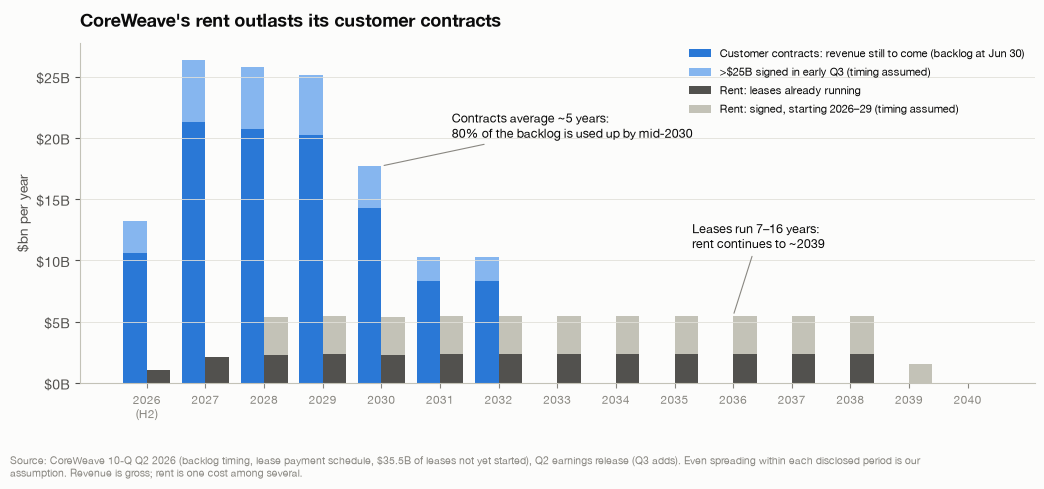

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.6))
w = 0.4
x = YEARS
ax.bar(x - w / 2, tl['contracted revenue'], w, color=BOND, label='Customer contracts: revenue still to come (backlog at Jun 30)')
ax.bar(x - w / 2, tl['Q3 adds (assumed timing)'], w, bottom=tl['contracted revenue'], color=RAMP[0], label='>$25B signed in early Q3 (timing assumed)')
ax.bar(x + w / 2, tl['rent: leases running'], w, color=INK2, label='Rent: leases already running')
ax.bar(x + w / 2, tl['rent: signed, not started'], w, bottom=tl['rent: leases running'], color=AXIS, label='Rent: signed, starting 2026–29 (timing assumed)')
ax.set_xticks(x, [('2026\n(H2)' if y == 2026 else str(y)) for y in x], fontsize=8.5)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'${y:,.0f}B'))
ax.grid(axis='x', visible=False)
ax.annotate('Contracts average ~5 years:\n80% of the backlog is used up by mid-2030', (2030, tl.loc[2030, ['contracted revenue', 'Q3 adds (assumed timing)']].sum()),
            xytext=(2031.2, 20), fontsize=9, color=INK, arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.annotate('Leases run 7–16 years:\nrent continues to ~2039', (2036, tl.loc[2036, 'rent total']), xytext=(2035.3, 11),
            fontsize=9, color=INK, arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.legend(loc='upper right', fontsize=8, ncol=1, bbox_to_anchor=(1, 1.02))
ax.set_ylabel('$bn per year')
ax.set_title("CoreWeave's rent outlasts its customer contracts", pad=12)
source_note(fig, 'Source: CoreWeave 10-Q Q2 2026 (backlog timing, lease payment schedule, $35.5B of leases not yet started), Q2 earnings release (Q3 adds). '
                 'Even spreading within each disclosed period is our assumption. Revenue is gross; rent is one cost among several.')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / '08_rent_vs_contracts.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/08_rent_vs_contracts.png`, above):
- **Through 2029, contracts dwarf rent.** Backlog revenue runs ~$20–27B a year against ~$2–5B of rent.
- **From 2031 the rent is bigger than the contracts.** From 2031 on, today's contracts (plus the Q3 adds) bring in ~$21B in total, and nothing after 2032. The rent due over the same years is ~$45B, and it keeps coming to ~2039.
- **This is the restaurant-chain risk, and it's already signed.** CoreWeave has committed to ~$65B of rent (plus up to $14.7B more at one site) on leases that run two to three times as long as its customer contracts. Every year after ~2030 it has to win new customers to fill those halls, at whatever the market pays then.
- **The bonds come due in that window.** The unsecured notes mature in 2030–2032 (`bonds.csv`). They'll be refinanced, or not, based on what the market then thinks the post-contract business is worth.

**Next:** what does an old GPU have to earn after its first contract for the lenders to be repaid?

## 3 · After a contract ends, what must an old GPU earn for lenders to be repaid?

**Why ask.** This is the question behind "at what level of AI bullishness does CoreWeave fall apart?" Total AI spending isn't what CoreWeave's lenders depend on. They depend on **what CoreWeave can charge for a GPU once its first contract ends.** That price can fall even while AI spending booms, if new supply (more GPUs, newer GPUs, customers' own chips) grows faster than demand.

**Method: follow $1 of equipment through its life.**
- **Cost and borrowing.** CoreWeave buys $1 of GPUs and data-center gear. It borrows ~68¢ of it: its debt ÷ everything it has built, at Jun 30. Shareholders cover the other ~32¢.
- **Interest** is ~9.5% a year: Q2 interest, including interest capitalized into construction, ÷ average debt. It builds up for ~6 months before the customer starts paying (assumption).
- **During the contract** (~5 years, the 10-K's weighted average), each year's cash after running costs pays interest first, then pays down the loan.
  - **"Cash after running costs" is Adjusted EBITDA:** revenue minus rent, power and staff, before interest.
  - We measure it per $1 of equipment, in two ways:
    - **Company average:** Q2 revenue per GW of active power, × the 59% Adjusted EBITDA margin, ÷ equipment cost per GW (from `fleet.csv`). This is ~18¢ per $1 a year. It may understate mature contracts, because some newly active capacity wasn't billing yet.
    - **The Meta contract behind the A3 loan (DDTL 4.0):** the lender deck sizes the loan at up to ~102% of cost with 1.2× cash coverage. With a 5.9% coupon and full repayment by Mar 2032, that implies ~30¢ per $1 a year. This is the best contract CoreWeave has, and it's pledged to the secured lenders.
- **After the contract** the GPU keeps working until the end of its useful life: 6 years in CoreWeave's accounts (`fleet.csv`), or longer if it holds up. It earns a share of the old contract's revenue; we call that share the **renewal level**. It's price × the share of capacity re-rented: half the GPUs re-rented at 80% of the old price is a 40% renewal level.
- **Running costs are fixed after the contract**, because the leases run on (§2). A GPU that sits idle still costs rent.
- **Result:** cash left when the GPU is worn out (assumed worth nothing), per $100 of equipment.
  - Below $0, lenders are short.
  - At $32, shareholders get back what they put in.

In [6]:
fl = fleet[fleet.issuer == 'CoreWeave'].gross_bn.sum()                  # GPUs, servers, data-center gear in service
gw_avg = (v('crwv_gw_start_q2') + v('crwv_gw_end_q2')) / 2
rev_gw = v('crwv_rev_q2') * 4 / gw_avg                                   # revenue per GW of active power, per year
cost_gw = fl / v('crwv_gw_end_q2')                                       # equipment cost per GW
MARGIN = v('crwv_adj_ebitda_q2') / v('crwv_rev_q2')
LOAN = v('crwv_debt_q2') / v('crwv_ppe_gross')                           # share of the build paid with debt
RATE = (v('crwv_interest_q2') + v('crwv_capint_q2')) * 4 / ((v('crwv_debt_q1') + v('crwv_debt_q2')) / 2)
r, n = v('ddtl_coupon') / 100, v('ddtl_amort_years')
CASH = {'Company average': MARGIN * rev_gw / cost_gw,
        'Meta contract (A3 loan)': v('ddtl_dscr') * v('ddtl_ltc') * r / (1 - (1 + r) ** -n)}
CONTRACT, INSTALL = v('crwv_contract_years'), v('install_years')
pd.Series({'revenue per GW per year ($bn)': rev_gw, 'equipment cost per GW ($bn)': cost_gw, 'Adjusted EBITDA margin': MARGIN,
           'share borrowed': LOAN, 'interest rate': RATE, 'cash per $1, company average': CASH['Company average'],
           'cash per $1, Meta contract': CASH['Meta contract (A3 loan)']}).round(3).to_frame('value')

,value
revenue per GW per year ($bn),8.240
equipment cost per GW ($bn),26.547
Adjusted EBITDA margin,0.586
share borrowed,0.676
interest rate,0.095
"cash per $1, company average",0.182
"cash per $1, Meta contract",0.303


In [7]:
def left_over(cash, renewal, life=6):
    # Per $1 of equipment: cash left after repaying the loan when the GPU wears out (negative = lenders short).
    # renewal = revenue after the contract, as a share of the contract's revenue.
    revenue = cash / MARGIN
    fixed = revenue - cash                          # rent, power, staff: fixed, because the leases run on
    debt = LOAN * (1 + RATE) ** INSTALL             # interest builds up before the customer pays
    for year in range(life):
        debt = debt * (1 + RATE) - (cash if year < CONTRACT else revenue * renewal - fixed)
    return -debt

# check: when the GPU dies with the contract, the result is the closed-form loan balance, whatever the renewal level
y5 = CASH['Company average']
closed = -(LOAN * (1 + RATE) ** (INSTALL + 5) - y5 * ((1 + RATE) ** 5 - 1) / RATE)
assert abs(left_over(y5, 0, 5) - closed) < 1e-12 and abs(left_over(y5, 1, 5) - closed) < 1e-12

GRID_X = np.linspace(0, 1.5, 1501)
def needed(cash, life, target):
    vals = np.array([left_over(cash, x, life) for x in GRID_X])
    return GRID_X[np.argmax(vals >= target)] if (vals >= target).any() else np.nan

h100_fall = (v('h100_price_2025_10') / v('h100_price_2024_01')) ** (1 / 1.75)   # Jan 2024 → Oct 2025 = 1.75 years
rows = []
for name, c in CASH.items():
    for life in [5, 6, 7, 8]:
        be = needed(c, life, 0)
        rows.append({'contract': name, 'GPU life (yrs)': life,
                     'left when contract ends, per $100': 100 * left_over(c, 0, min(life, int(CONTRACT))),
                     'renewal level for lenders to be whole': be,
                     'same, as max yearly price fall': (1 - be ** (1 / CONTRACT)) if be > 0 else np.nan,
                     'renewal level for shareholders to break even': needed(c, life, 1 - LOAN)})
be_tab = pd.DataFrame(rows).set_index(['contract', 'GPU life (yrs)'])
print(f'H100 rental prices fell {1 - h100_fall:.0%} a year; five years of that leaves {h100_fall ** CONTRACT:.0%} of the starting price.')
be_tab.style.format({'left when contract ends, per $100': '{:+.1f}', 'renewal level for lenders to be whole': '{:.0%}',
                     'same, as max yearly price fall': '{:.0%}', 'renewal level for shareholders to break even': '{:.0%}'}, na_rep='—')

H100 rental prices fell 19% a year; five years of that leaves 34% of the starting price.


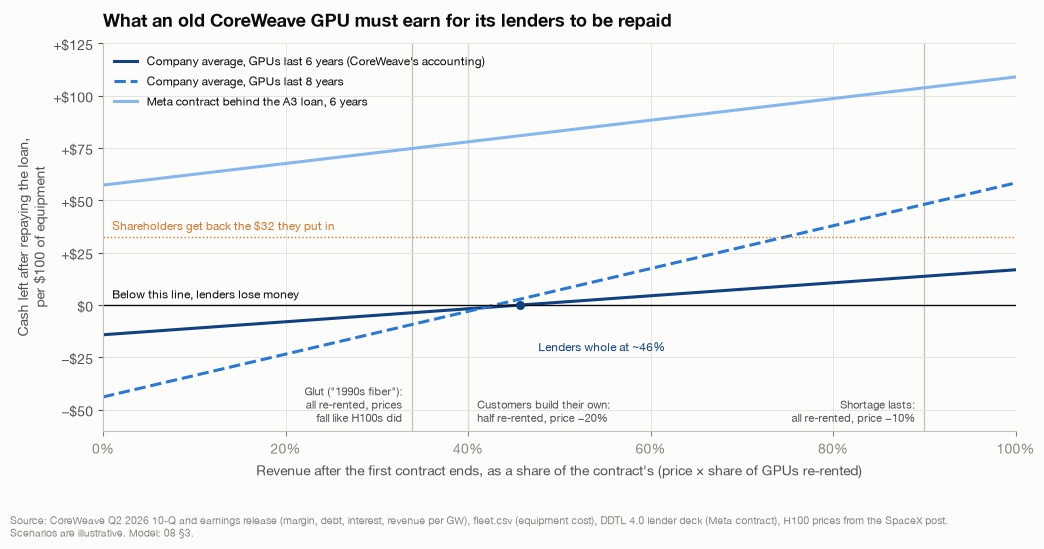

In [8]:
SCEN = {'Glut ("1990s fiber"):\nall re-rented, prices\nfall like H100s did': h100_fall ** CONTRACT,
        'Customers build their own:\nhalf re-rented, price −20%': 0.5 * 0.8,
        'Shortage lasts:\nall re-rented, price −10%': 0.9}
xs = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(10.5, 5.2))
lines = [('Company average, GPUs last 6 years (CoreWeave\'s accounting)', CASH['Company average'], 6, RAMP[2], '-'),
         ('Company average, GPUs last 8 years', CASH['Company average'], 8, RAMP[1], '--'),
         ('Meta contract behind the A3 loan, 6 years', CASH['Meta contract (A3 loan)'], 6, RAMP[0], '-')]
for lab, c, life, colr, ls in lines:
    ax.plot(xs * 100, [100 * left_over(c, x, life) for x in xs], color=colr, ls=ls, lw=2.2, label=lab)
ax.axhline(0, color=INK, lw=1)
ax.axhline(100 * (1 - LOAN), color=EQUITY, lw=1, ls=':')
ax.text(1, 2, 'Below this line, lenders lose money', fontsize=8.5, color=INK, va='bottom')
ax.text(1, 100 * (1 - LOAN) + 2, f'Shareholders get back the ${100 * (1 - LOAN):.0f} they put in', fontsize=8.5, color=EQUITY, va='bottom')
for lab, x, side in zip(SCEN, SCEN.values(), ['right', 'left', 'right']):   # labels sit on alternating sides so close lines don't collide
    ax.axvline(x * 100, color=AXIS, lw=0.9, zorder=0)
    ax.text(x * 100 + (-1 if side == 'right' else 1), -57, lab, fontsize=8, color=INK2, va='bottom', ha=side)
be6 = be_tab.loc[('Company average', 6), 'renewal level for lenders to be whole']
ax.scatter([be6 * 100], [0], color=RAMP[2], zorder=4, s=30)
ax.annotate(f'Lenders whole at ~{be6:.0%}', (be6 * 100, 0), xytext=(be6 * 100 + 2, -22), fontsize=8.5, color=RAMP[2])
ax.set_xlim(0, 100); ax.set_ylim(-60, 125)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(100))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{'+' if y > 0 else '−' if y < 0 else ''}${abs(y):,.0f}"))
ax.set_xlabel("Revenue after the first contract ends, as a share of the contract's (price × share of GPUs re-rented)")
ax.set_ylabel('Cash left after repaying the loan,\nper $100 of equipment')
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('What an old CoreWeave GPU must earn for its lenders to be repaid', pad=12)
source_note(fig, 'Source: CoreWeave Q2 2026 10-Q and earnings release (margin, debt, interest, revenue per GW), fleet.csv (equipment cost), DDTL 4.0 lender deck (Meta contract), '
                 'H100 prices from the SpaceX post. Scenarios are illustrative. Model: 08 §3.')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / '08_renewal_breakeven.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/08_renewal_breakeven.png` and the table above):
- **The first contract alone almost repays the loan, but not quite.** On the company-average economics, when a 5-year contract ends the lenders are still owed ~$1 per $100 of equipment. Shareholders' $32 is gone. The contract pays for the hardware and the interest, and nothing more.
- **Lenders are made whole only if the old GPU earns ≥ ~46% of its old contract revenue** in its last year (6-year life). A 5-year-old GPU at 46% of its launch price means prices fell ~14% a year. **H100 rental prices fell ~19% a year.** *(Revised in 10 §1: H100 rents bottomed in early 2026 and rose; from Jan 2024 to Nov 2026 they are roughly flat, −5% to +10% a year depending on the measure.)* If that pattern holds, lenders come out short even with every GPU re-rented, in a world where AI demand never stopped growing. That's the 1990s fiber story (see below).
- **"Customers build their own"** (half the GPUs re-rented, at 80% of the price) lands at ~40%, also short. Only **"shortage lasts"** clears comfortably.
- **Longer GPU lives help shareholders far more than lenders.** At 8 years, lenders need about the same ~43–46%. Shareholders get their money back at ~75%, against ~94% at 7 years and never at 6.
- **The Meta contract is a different business.** It pays ~30¢ per $1 of equipment a year, against ~18¢ on average, and repays its loan with ~$57 to spare per $100 even with zero renewal. That's why that loan is rated A3. **But it's pledged to the secured lenders.** The B+ unsecured bonds are repaid from everything else, which looks like the company average.
- **At what level of AI bullishness does CoreWeave fall apart?** Not a level of spending. It falls apart **when the price of renting a given GPU falls faster than ~14% a year**, which is what happens whenever supply outruns demand, however big demand is.

**In plain terms, for the post:** in the late 1990s, companies borrowed heavily to lay fiber-optic cable because internet traffic was exploding. The traffic did explode. But everyone laid cable at once, the price of carrying data collapsed, and many of the builders went bankrupt. The bet on demand was right; the bet on prices was wrong. CoreWeave's lenders are making the second bet.

**Caveats specific to this section:**
- Revenue per GW uses average active power in Q2. Some of that capacity wasn't billing yet, so the company-average line probably understates mature contracts. The true average sits between the two solid lines.
- This follows one batch of equipment. CoreWeave as a whole keeps buying new GPUs with new borrowing, so its total debt doesn't shrink the way one batch's does (06's pause test).
- An old GPU's value at the end of its life is set to zero, and running costs to fully fixed.

**Next:** Nebius sells the same thing to some of the same customers. How did it fund the build?


### 3b · What is a paid-off GPU worth: CoreWeave vs. SpaceX

**Why ask.** After 5–6 years a GPU is fully depreciated: in the accounts it costs nothing, so anything it earns looks like profit. Many H100s will still work at that age. SpaceX owns a lot of them; CoreWeave needs every dollar it can get. Who benefits?

**Depreciation is the part that doesn't matter.** It's an accounting charge, not cash. A paid-off GPU only adds cash if it earns more than it costs to keep running. The two companies' running costs differ in one way: **rent.**
- **CoreWeave rents its data centers.** Fixed rent was ~20% of Q2 revenue (operating + finance lease cost ÷ revenue). Its other running costs (power, staff, landlords' usage charges, overhead) are the other ~21%, for 41% in total (1 − the 59% margin).
- **SpaceX mostly owns its data centers**, so it pays no rent on them. We assume its other running costs match CoreWeave's ~21% of revenue. (SpaceX doesn't break them out.)
- **Power alone** is the floor: ~1.3 kW per H100 (Nvidia's DGX spec) × 1.3 for cooling × ~8¢/kWh ≈ $0.13 an hour, ~5% of an H100's Jan 2024 rent. If staff and overhead don't shrink when old GPUs are switched off, this is closer to the true cost of keeping one running.

**Method.** One H100, from age 0 to 10, its revenue as a share of what it earned when new:
- **CoreWeave:** the contract price for 5 years, then the market price.
- **SpaceX:** sells "at effectively the spot market rate" (06), so the market price from day one.
- **Market price:** falls ~19% a year, the H100's history (§3).

We add up the cash each company keeps in years 6–10, after the GPU is fully depreciated, per $100 of what the GPU earned in its first year. A GPU is switched off once it earns less than its running costs, excluding rent, since rent is owed either way.


In [9]:

RENT = (v('crwv_oplease_cost_q2') + v('crwv_finlease_cost_q2')) / v('crwv_rev_q2')    # fixed rent, share of revenue
RUN_ALL = 1 - MARGIN                                                                   # every cash running cost, incl. rent
RUN_EX_RENT = RUN_ALL - RENT                                                           # power, staff, landlords' usage charges, overhead
POWER = v('h100_kw') * v('pue') * v('power_price') / v('h100_price_2024_01')          # power alone, share of an H100's Jan 2024 rent

age = np.arange(0, 11)
market = h100_fall ** age                                  # an H100's rent at each age, as a share of its rent when new
crwv_rev = np.where(age < CONTRACT, 1.0, market)           # 5-year contract, then the market
paid_off = age >= 6                                        # fully depreciated (CoreWeave 6 years; SpaceX 5-6)

def kept(rev, cost):    # cash over years 6-10 per $100 of first-year revenue; switched off when it can't cover cost
    return 100 * np.clip(rev - cost, 0, None)[paid_off].sum()

gpu_cash = kept(market, RUN_EX_RENT)                       # same GPU, same physics, either company
tail = pd.DataFrame({
    'old GPU earns, after running costs (ex rent)': [gpu_cash, gpu_cash, kept(market, POWER)],
    'rent owed on its space': [-100 * RENT * paid_off.sum(), 0, 0]},
    index=['CoreWeave', 'SpaceX (no rent; other costs like CoreWeave)', 'SpaceX if only power counts'])
tail['cash kept, years 6-10'] = tail.sum(axis=1)
print(f'Running costs, share of revenue when new: all {RUN_ALL:.0%} = rent {RENT:.0%} + other {RUN_EX_RENT:.0%}; power alone {POWER:.0%}.')
print(f'The H100 covers costs ex rent until age {np.log(RUN_EX_RENT) / np.log(h100_fall):.1f}, all costs until {np.log(RUN_ALL) / np.log(h100_fall):.1f}, power alone until {np.log(POWER) / np.log(h100_fall):.0f}.')
tail.round(0)


Running costs, share of revenue when new: all 41% = rent 20% + other 21%; power alone 5%.
The H100 covers costs ex rent until age 7.1, all costs until 4.1, power alone until 14.


,"old GPU earns, after running costs (ex rent)",rent owed on its space,"cash kept, years 6-10"
CoreWeave,7.0,-100.0,-94.0
SpaceX (no rent; other costs like CoreWeave),7.0,0.0,7.0
SpaceX if only power counts,69.0,0.0,69.0


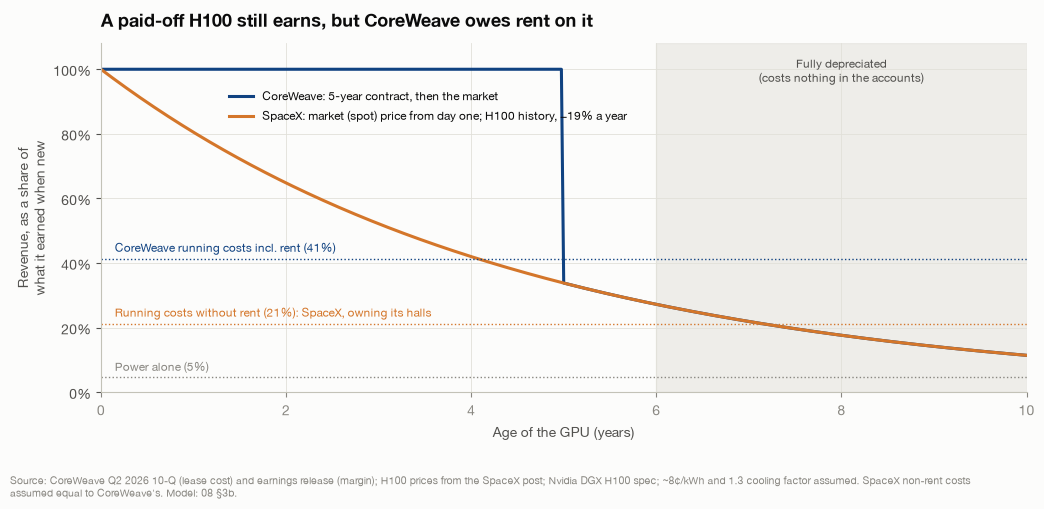

In [10]:

fig, ax = plt.subplots(figsize=(10.5, 4.8))
ax.axvspan(6, 10, color=GRID, alpha=0.5, zorder=0)
ax.text(8, 1.04, 'Fully depreciated\n(costs nothing in the accounts)', ha='center', va='top', fontsize=8.5, color=INK2)
t = np.linspace(0, 10, 401)
ax.plot(t, np.where(t < CONTRACT, 1.0, h100_fall ** t), color=RAMP[2], lw=2.2, label='CoreWeave: 5-year contract, then the market')
ax.plot(t, h100_fall ** t, color=EQUITY, lw=2.2, label='SpaceX: market (spot) price from day one; H100 history, −19% a year')
for y, lab, colr in [(RUN_ALL, f'CoreWeave running costs incl. rent ({RUN_ALL:.0%})', RAMP[2]),
                     (RUN_EX_RENT, f'Running costs without rent ({RUN_EX_RENT:.0%}): SpaceX, owning its halls', EQUITY),
                     (POWER, f'Power alone ({POWER:.0%})', MUTED)]:
    ax.axhline(y, color=colr, lw=1, ls=':')
    ax.text(0.15, y + 0.012, lab, ha='left', va='bottom', fontsize=8.5, color=colr)
ax.set_xlim(0, 10); ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel('Age of the GPU (years)'); ax.set_ylabel("Revenue, as a share of\nwhat it earned when new")
ax.legend(loc='upper right', bbox_to_anchor=(0.58, 0.9), fontsize=8.5)
ax.set_title('A paid-off H100 still earns, but CoreWeave owes rent on it', pad=12)
source_note(fig, 'Source: CoreWeave Q2 2026 10-Q (lease cost) and earnings release (margin); H100 prices from the SpaceX post; Nvidia DGX H100 spec; ~8¢/kWh and 1.3 cooling factor assumed. '
                 'SpaceX non-rent costs assumed equal to CoreWeave\'s. Model: 08 §3b.')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / '08_paid_off_gpu.png', dpi=200, bbox_inches='tight')
plt.show()



**What this shows** (`charts/08_paid_off_gpu.png` and the table above):
- **The same old H100 makes the same cash at either company.** After its non-rent running costs it adds ~$7 per $100 of first-year revenue in years 6–10. It covers those costs until about age 7. If only power counts, it adds ~$69 and is worth running past age 10.
- **At SpaceX, that cash is kept.** There's no rent on its own halls, so a paid-off H100 is pure upside: anywhere from a little (~$7) to most of a year's original revenue (~$69).
- **At CoreWeave, rent eats it.** Its rent is ~20% of revenue every year, owed whether the GPU runs or not. Over years 6–10 that's ~$100 per $100, so the old GPU **shrinks a loss instead of making a profit** (net ~−$94). *(Revised in 10 §5–6: this assumes rents fall ~19% a year. At today's A100 prices, a 6-year-old GPU still earns ~19¢ a year per $1 it cost, after power, data-center rent and overhead. CoreWeave has re-signed an A100 contract to 2029, and its asset-level loans are paid off within the first contract.)* It's still worth switching on, because something is better than an empty hall paying rent. But it doesn't pay the bondholders.
- **The contract cuts both ways.** CoreWeave earns the full price for 5 years while SpaceX's spot revenue falls from year one. SpaceX depends on the old-GPU years more, but it gets to keep what they earn.
- **Power can retire a working GPU early, at both companies.** If a newer chip could use the same power to earn several times more, the old H100 comes out even if it still works. SpaceX is power-constrained (06 §6). So the large figure for SpaceX holds only while it has power to spare.
- **For SpaceX's accounts:** once its H100s are fully depreciated, reported AI operating profit jumps, because depreciation stops but revenue doesn't. Cash doesn't change. Bondholders should read EBITDA and cash flow, as 06 does.
- **Revises 06 §2 (pause test):** "upkeep = fleet cost ÷ useful life" assumes every GPU is replaced on schedule. For SpaceX, which owns its halls, old GPUs can run past their accounting life, so 06's upkeep figure for SpaceX is a ceiling. For CoreWeave the stretch is worth little, because of rent.

**Caveats.** SpaceX's non-rent running costs are assumed, not reported, and some of its AI infrastructure is under sale-leasebacks (06, "Other financings"), which act like rent. The power cost uses a typical US industrial rate; SpaceX's on-site gas at Colossus may differ. Hardware failures will retire some GPUs before age 10.


## 4 · How does Nebius fund the same business?

**Why ask.** Nebius rents Nvidia GPUs to AI companies, as CoreWeave does, and Microsoft and Meta are customers of both. But it has no straight bonds to add to our yield comparison (02–03). Its debt is convertible notes plus one small secured loan. So we use it as a contrast in funding: if the business is the same, how much of the risk did each company put on lenders?

**Method.** Both balance sheets at Jun 30, 2026, from the filings. "Who paid for the build" splits the money each company has raised into three sources:
- **Lenders:** debt.
- **Shareholders:** book equity, i.e. what shareholders put in, less losses so far.
- **Customers:** prepayments, i.e. deferred revenue: cash customers paid up front for future capacity.

Leases are left out of both. They're rent, not money raised. Nebius's are much smaller: $1.5B of operating lease liabilities against CoreWeave's $16.3B, plus CoreWeave's $35.5B not yet started.

In [11]:
crwv_unsec = bonds[(bonds.issuer == 'CoreWeave') & (bonds.seniority == 'senior unsecured')].coupon
cmp = pd.DataFrame({
    'CoreWeave': {'revenue, Q2 × 4 ($bn)': 4 * v('crwv_rev_q2'), 'Adjusted EBITDA margin': v('crwv_adj_ebitda_q2') / v('crwv_rev_q2'),
                  'lenders: debt ($bn)': issuers.loc['CoreWeave', 'debt_face_bn'], 'shareholders: book equity ($bn)': v('crwv_equity'),
                  'customers: prepayments ($bn)': v('crwv_deferred_rev'), 'cash ($bn)': issuers.loc['CoreWeave', 'cash_securities_bn'],
                  'backlog / RPO ($bn)': RPO, 'top 3 customers, share of Q2 revenue': v('crwv_top3_share_q2'),
                  'interest, Q2 × 4 ($bn)': 4 * v('crwv_interest_q2'), 'coupon on unsecured debt': f'{crwv_unsec.min():g}–{crwv_unsec.max():g}% (bonds)'},
    'Nebius': {'revenue, Q2 × 4 ($bn)': 4 * v('nbis_rev_q2'), 'Adjusted EBITDA margin': v('nbis_ai_adj_ebitda_q2') / v('nbis_rev_q2'),
               'lenders: debt ($bn)': v('nbis_debt'), 'shareholders: book equity ($bn)': v('nbis_equity'),
               'customers: prepayments ($bn)': v('nbis_deferred_rev'), 'cash ($bn)': v('nbis_cash'),
               'backlog / RPO ($bn)': v('nbis_rpo'), 'top 3 customers, share of Q2 revenue': v('nbis_top3_share_q2'),
               'interest, Q2 × 4 ($bn)': 4 * v('nbis_interest_q2'), 'coupon on unsecured debt': f"{v('nbis_conv_coupon_low'):g}–{v('nbis_conv_coupon_high'):g}% (convertibles)"}})
SRC = ['lenders: debt ($bn)', 'shareholders: book equity ($bn)', 'customers: prepayments ($bn)']
mix = cmp.loc[SRC].astype(float) / cmp.loc[SRC].astype(float).sum()
cmp.loc['debt ÷ revenue (×)'] = cmp.loc['lenders: debt ($bn)'] / cmp.loc['revenue, Q2 × 4 ($bn)']
cmp.loc['net debt ($bn)'] = cmp.loc['lenders: debt ($bn)'] - cmp.loc['cash ($bn)']
cmp

,CoreWeave,Nebius
"revenue, Q2 × 4 ($bn)",10.3,2.3292
Adjusted EBITDA margin,0.586408,0.490641
lenders: debt ($bn),35.55,8.499
shareholders: book equity ($bn),5.02,10.3405
customers: prepayments ($bn),9.692,5.9752
cash ($bn),5.539,8.0421
backlog / RPO ($bn),103.7,37.4906
"top 3 customers, share of Q2 revenue",0.72,0.59
"interest, Q2 × 4 ($bn)",2.56,0.4764
coupon on unsecured debt,9–9.75% (bonds),1.25–2.625% (convertibles)


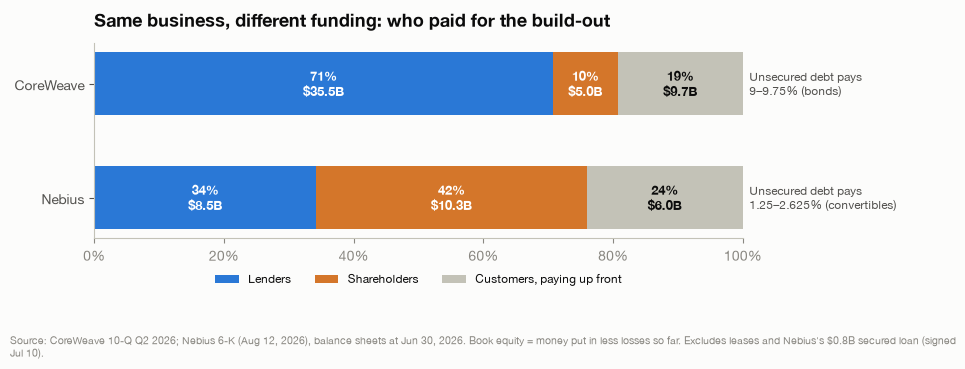

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 3.4))
parts = [('lenders: debt ($bn)', BOND, 'Lenders'), ('shareholders: book equity ($bn)', EQUITY, 'Shareholders'),
         ('customers: prepayments ($bn)', AXIS, 'Customers, paying up front')]
for i, co in enumerate(['CoreWeave', 'Nebius']):
    left = 0
    for key, colr, lab in parts:
        w = mix.loc[key, co]
        ax.barh(i, w, left=left, color=colr, height=0.55, label=lab if i == 0 else None)
        ax.text(left + w / 2, i, f'{w:.0%}\n${cmp.loc[key, co]:,.1f}B', ha='center', va='center', fontsize=9,
                color='white' if colr != AXIS else INK, fontweight='bold')
        left += w
ax.text(1.01, 0, f"Unsecured debt pays\n{cmp.loc['coupon on unsecured debt', 'CoreWeave']}", va='center', fontsize=8.5, color=INK2)
ax.text(1.01, 1, f"Unsecured debt pays\n{cmp.loc['coupon on unsecured debt', 'Nebius']}", va='center', fontsize=8.5, color=INK2)
ax.set_yticks([0, 1], ['CoreWeave', 'Nebius']); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.grid(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8.5)
ax.set_title('Same business, different funding: who paid for the build-out', pad=12)
source_note(fig, 'Source: CoreWeave 10-Q Q2 2026; Nebius 6-K (Aug 12, 2026), balance sheets at Jun 30, 2026. Book equity = money put in less losses so far. '
                 'Excludes leases and Nebius\'s $0.8B secured loan (signed Jul 10).')
fig.tight_layout(rect=(0, 0.06, 0.87, 1))
fig.savefig(CHARTS / '08_funding_mix.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/08_funding_mix.png` and the table above):
- **Lenders paid for ~71% of CoreWeave's build, and ~34% of Nebius's.** Nebius raised most of its money from shareholders: ~$4.8B of new stock and warrants in H1 2026 alone.
- **Both owe about 3.5× a year's revenue, so the gap isn't the size of the debt.** It's the cushion. Nebius holds about as much cash as it owes ($8.0B against $8.5B of debt), while CoreWeave owes ~$30B more than it holds. And Nebius's shareholders have ~$10B of their own money at stake, against CoreWeave's ~$5B.
- **How the lenders get paid differs as much as how much they lent.** CoreWeave's unsecured bonds pay 9–9.75% in cash. Nebius's convertible notes pay 1.25–2.6%, because the holder can swap them for stock if the shares rise. Nebius pays its lenders with a share of the upside instead of interest.
- **Customers prepay at both** (~$6B at Nebius, ~$10B at CoreWeave). At Nebius that's a quarter of all the money raised.
- **Nebius is not lower-risk as a business.** Its top three customers were 59% of Q2 revenue, and its backlog ($37.5B, plus >$25B signed in early Q3) leans on Microsoft. The difference is who absorbs the loss if §3's prices fall: at Nebius mostly shareholders, at CoreWeave lenders sooner.
- **For the post's ladder:** Nebius is the neocloud version of Alphabet vs. SpaceX in 06, the same build-out with a much bigger cushion of shareholders' money.

## 5 · Could CoreWeave sell stock to repay its bonds?

**Why ask.** §1–3 say CoreWeave's lenders are repaid only if GPUs stay scarce. That's the bear case, so here's the bull case for the bonds. A company with a ~$27B stock market value doesn't have to repay debt from operations. It can sell new shares and hand the cash to lenders. Shareholders get diluted, bondholders get paid. If that route is open whatever GPU prices do, the ~15% yield (03 §7) is a better deal than "a bet on scarcity" makes it sound.

**What CoreWeave has already done** (Q2 10-Q; 8-Ks and 424B5 of Sep 17–22, 2026, cached in `data/edgar/`):
- **Sold stock:** $1.5B at the IPO (Mar 2025) and $3.0B in H1 2026 private placements, $2.0B of it to **Nvidia at $87.20 a share** (Jan 2026).
- **Set up a stock-sale program (an "ATM", or at-the-market offering) in Sep 2026:** up to **35M shares**, sold into the market over time. The stated uses include "repayment of indebtedness" and "migrating our enterprise credit profile toward investment grade." No sales were allowed until ~Oct 17, and how much has been sold won't be known until the Q3 10-Q (~Nov 10).
- **Sold convertibles:** $10.8B of unsecured notes at 1.75–2.875% that turn into stock if the share price rises enough. That's why they're cheap: buyers accept a low coupon in exchange for the upside.

**Method.** Three amounts CoreWeave might need to raise, from the Jun 30 balance sheet plus the Sep 2026 convertible:
1. **The 2028 wall:** debt due by end-2028 minus cash on hand (06 §1).
2. **Every unsecured bond and convertible at the parent:** the claims that rank with yours.
3. **All debt.**

For each, the share of the company that new shareholders would end up owning, at different share prices:

$$\text{share of company sold} = \frac{\text{amount raised}}{\text{market value before the sale} + \text{amount raised}}$$

This is generous to CoreWeave in two ways. It assumes no discount for selling a large block, and it assumes the share price doesn't fall when everyone sees the company selling stock to pay debts.

The prices tested:
- what Nvidia paid ($87.20);
- the latest close (Nov 10, $48.73);
- the falls the options market prices by Jan 2029 (06 §8, `data/crash_odds.csv`).

In [13]:
SH = issuers.loc['CoreWeave', 'shares_mn'] / 1e3                       # bn shares, Class A + B (Jul 31)
PX = pd.read_csv('data/merton_inputs.csv').set_index('issuer').loc['CoreWeave', 'price']
PX_DATE = pd.read_csv('data/spreads.csv', parse_dates=['as_of']).query("kind == 'trade'").as_of.max()
fund = pd.read_csv('data/fundamentals.csv', index_col=0).loc['CoreWeave']
crash = pd.read_csv('data/crash_odds.csv').query("issuer == 'CoreWeave'").set_index('expiry').iloc[-1]   # Jan 2029 expiry

UNSEC = ['crwv_notes_2030', 'crwv_notes_2031_900', 'crwv_notes_2031_975', 'crwv_notes_2032_9625', 'crwv_notes_2032_eur']
CONV = ['crwv_conv_2031', 'crwv_conv_2032', 'crwv_conv_2033']
stack = pd.Series({
    'secured GPU loans (DDTLs, recourse)': v('crwv_ddtl_secured'),
    'equipment financing (OEM)': v('crwv_oem_fin'),
    'Meta-contract loan (DDTL 4.0, non-recourse)': v('crwv_ddtl4_nonrecourse'),
    'unsecured bonds (yours)': sum(v(k) for k in UNSEC),
    'unsecured convertibles (rank with yours)': sum(v(k) for k in CONV)}, name='$bn')
NEED = {'2028 wall: due by end-2028 − cash': fund['debt due by end-2028 ($bn)'] - fund['cash ($bn)'],
        'every unsecured bond + convertible': stack.iloc[-2:].sum(),
        'all debt': issuers.loc['CoreWeave', 'debt_face_bn'] + v('crwv_conv_2033')}
PRICES = {f"Nvidia's price (${v('crwv_nvda_placement_price'):.2f})": v('crwv_nvda_placement_price'),
          f'{PX_DATE:%b %-d} close (${PX:.2f})': PX,
          f"−50% (options: {crash['P(fall ≥ 50%)']:.0%} odds by Jan 2029)": PX * 0.5,
          f"−75% (options: {crash['P(fall ≥ 75%)']:.0%} odds)": PX * 0.25}
sold = lambda need, px: need / (SH * px + need)
dil = pd.DataFrame({k: {lab: sold(n, px) for lab, px in PRICES.items()} for k, n in NEED.items()})
atm_bn = v('crwv_atm_shares') / 1e3 * PX
votes_b = 10 * (SH - 0.458871690)                                          # Class B = total − Class A (424B5)
print(f'Market value at ${PX:.2f}: ${SH * PX:.1f}B on {SH * 1e3:.0f}M shares. Amounts needed: ' + ', '.join(f'{k} ${n:.1f}B' for k, n in NEED.items()) + '.')
print(f"The ATM's 35M shares raise ~${atm_bn:.1f}B at ${PX:.2f}: {atm_bn / NEED['2028 wall: due by end-2028 − cash']:.0%} of the 2028 wall, {v('crwv_atm_shares') / 1e3 / SH:.1%} of the shares.")
print(f"Stock sold so far: ${v('crwv_ipo_proceeds') + v('crwv_private_placements_h1'):.1f}B (IPO + 2026 placements). Convertibles: ${stack.iloc[-1]:.1f}B, converting at "
      f"${v('crwv_conv_2033_price'):.2f}-{v('crwv_conv_2032_price'):.2f} a share vs. ${PX:.2f} today.")
print(f'Co-founders\' Class B votes: {votes_b / (votes_b + 0.458871690):.0%} of the total.')
assert abs(sold(SH * PX, PX) - 0.5) < 1e-12                                # raising your whole market value = selling half
display(stack.to_frame().style.format('{:.1f}'))
dil.assign(price=list(PRICES.values())).to_csv('data/equity_backstop.csv')   # handoff to research.ipynb
dil.style.format('{:.0%}')

Market value at $48.73: $26.9B on 552M shares. Amounts needed: 2028 wall: due by end-2028 − cash $9.5B, every unsecured bond + convertible $20.8B, all debt $39.8B.
The ATM's 35M shares raise ~$1.7B at $48.73: 18% of the 2028 wall, 6.3% of the shares.
Stock sold so far: $4.5B (IPO + 2026 placements). Convertibles: $10.8B, converting at $97.85-119.60 a share vs. $48.73 today.
Co-founders' Class B votes: 67% of the total.


,$bn
"secured GPU loans (DDTLs, recourse)",10.8
equipment financing (OEM),5.1
"Meta-contract loan (DDTL 4.0, non-recourse)",2.8
unsecured bonds (yours),10.0
unsecured convertibles (rank with yours),10.8


,2028 wall: due by end-2028 − cash,every unsecured bond + convertible,all debt
Nvidia's price ($87.20),16%,30%,45%
Nov 10 close ($48.73),26%,44%,60%
−50% (options: 48% odds by Jan 2029),41%,61%,75%
−75% (options: 37% odds),59%,76%,86%


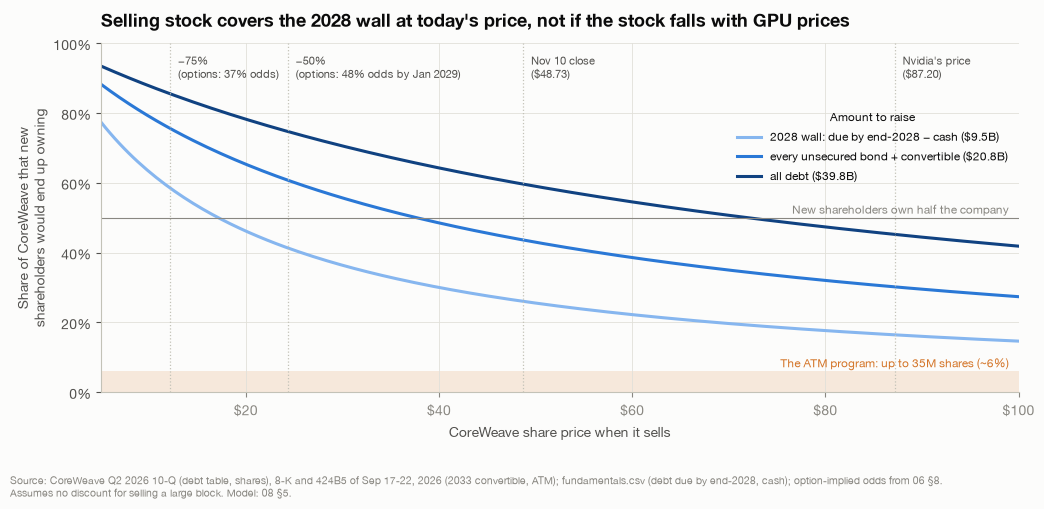

In [14]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
px = np.linspace(5, 100, 200)
for (lab, n), col in zip(NEED.items(), RAMP):
    ax.plot(px, 100 * sold(n, px), color=col, lw=2.2, label=f'{lab} (${n:.1f}B)')
for lab, p in PRICES.items():
    ax.axvline(p, color=AXIS, lw=0.9, ls=':')
    ax.text(p + 0.8, 97, lab.replace(' (', '\n('), fontsize=8, color=INK2, va='top')
atm_pct = 100 * v('crwv_atm_shares') / 1e3 / (SH + v('crwv_atm_shares') / 1e3)
ax.axhspan(0, atm_pct, color=EQUITY, alpha=0.15, lw=0)
ax.text(99, atm_pct + 1.2, f'The ATM program: up to 35M shares (~{atm_pct:.0f}%)', ha='right', fontsize=8.5, color=EQUITY)
ax.axhline(50, color=MUTED, lw=0.8)
ax.text(99, 51.2, 'New shareholders own half the company', ha='right', fontsize=8.5, color=MUTED)
ax.set_xlim(5, 100); ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(100))
ax.set_xlabel('CoreWeave share price when it sells'); ax.set_ylabel('Share of CoreWeave that new\nshareholders would end up owning')
ax.legend(loc='upper right', bbox_to_anchor=(1, 0.84), fontsize=8.5, title='Amount to raise', title_fontsize=8.5)
ax.set_title('Selling stock covers the 2028 wall at today\'s price, not if the stock falls with GPU prices', pad=12)
source_note(fig, 'Source: CoreWeave Q2 2026 10-Q (debt table, shares), 8-K and 424B5 of Sep 17-22, 2026 (2033 convertible, ATM); fundamentals.csv (debt due by end-2028, cash); '
                 'option-implied odds from 06 §8. Assumes no discount for selling a large block. Model: 08 §5.')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / '08_equity_backstop.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/08_equity_backstop.png` and the tables above):
- **At today's price, selling stock can cover the 2028 wall.** ~$9.5B is due by end-2028 beyond the cash on hand. At $48.73 CoreWeave could raise it by selling about a quarter of the company (~26%), and about 16% at Nvidia's $87.20. So the bonds aren't *only* a scarcity bet. Management has opened the tap (the ATM), named debt repayment and an investment-grade rating as the reasons, and has sold $10.8B of convertibles in a year. That's a real point for the bonds, especially the 2030 and early-2031 notes that come due first.
- **But the ATM is small, and repaying every bond needs much more.** 35M shares raise ~$1.7B at $48.73, under a fifth of the 2028 wall. Repaying every unsecured bond and convertible (~$21B, yours included) would mean selling ~44% of the company today, and repaying all debt ~60%.
- **The backstop shrinks in exactly the world where you need it.** The stock is worth something because the market thinks GPUs might stay scarce. If rental prices fall the way H100s' did (§3), the stock falls too. The options market gives a ~48% chance of a ≥50% fall by Jan 2029, and ~37% of a ≥75% fall. At −75% the 2028 wall alone means selling more than half the company (~59%). That ~37% is close to the bonds' own implied default odds over the same 2.2 years (~30%, 06 §8). **The bad worlds for the bonds and the bad worlds for the stock are the same worlds.** That's why the stock and the bonds price similar default risk (~1,136 vs. ~1,041bp, 06 §7).
- **Dilution buys time; it doesn't fix the business.** Stock sold in 2027 pays the 2028 wall, but the rent still outlasts the contracts from 2031 (§2), and old GPUs still have to earn ≥ ~46% of their old revenue (§3). Your 2031 notes mature after the contracts run out.
- **Nobody has to do it.** No covenant makes CoreWeave sell stock to pay you. The co-founders hold ~67% of the votes through Class B shares, and they have their own reasons not to dilute. The convertibles are also a reminder of what CoreWeave sells when it does raise. They convert at $97.85–119.60 against a ~$49 stock, so for now they behave like $10.8B of extra unsecured debt ranking alongside yours, not like equity.

**The other levers, checked:**

| Lever | Helps the bonds? | Depends on scarcity? |
|---|---|---|
| **Stock sales (ATM, placements)** | Yes, directly, if management chooses to | Yes: proceeds shrink as the stock falls |
| **Nvidia** | Partly. A $2.0B shareholder at $87.20, and (per press, Sep 2025) a **$6.3B order to buy capacity no other customer takes, through Apr 2032**. That's the one lever that pays out *because* demand is weak. | Less, but $6.3B is small next to ~$45B of rent due from 2031 (§2), and Nvidia's obligation is contingent |
| **More convertibles** | Short-term cash, at the cost of more claims ranking with yours | Yes: they only sell while buyers see upside in the stock |
| **Customer prepayments** ($9.7B deferred revenue at Jun 30) | Funds builds without lenders | Yes: they come with new contracts |
| **Secured GPU loans** | Fund growth, but rank ahead of you | Yes: sized off contracts |
| **A sale of the company** | Possibly, if a stronger buyer takes on the debt. Speculative; no evidence of one | Yes: the price depends on the outlook |

**So, does the equity route make ~15% worth it?** It improves the odds for the *near* maturities, and it's why a default before 2028 is far from certain. It doesn't change the answer for the 2031–32 notes. The share price is itself a bet on GPU scarcity, so selling stock is a second claim on the same outcome, not a separate safety net. The one independent lever is Nvidia's capacity order. It's real but small, and its terms come from press, not the filing.

**Next:** the Q3 10-Q (~Nov 10) will show how many ATM shares were sold, the Sep 30 cash balance including the $4.2B convertible, and the updated maturity schedule. Re-run this section then.

## Findings, by section

**§1 · Customers** (`08_customers.png`)
- The named contracts are Meta (up to ~$35B, AA-), OpenAI (~$22B, private) and Jane Street ($6B, private). The remaining ~$40B of the $104B backlog is Microsoft, Anthropic and others, with no amounts disclosed.
- Every AI-model customer is also building its own capacity or buying non-Nvidia chips: Meta's campuses, OpenAI's Stargate and Broadcom chips, Anthropic's Google TPUs and Amazon Trainium, Microsoft's Maia and other neoclouds. CoreWeave is the supplier they use when they can't build fast enough.

**§2 · Rent vs. contracts** (`08_rent_vs_contracts.png`)
- Customer contracts average ~5 years; 80% of today's backlog is used up by mid-2030.
- ~$65B of rent is committed (plus up to $14.7B more at one site) on leases running to ~2039. From 2031 on, ~$45B of rent is due against ~$21B of contracted revenue. After ~2030, CoreWeave has to win new customers every year just to cover rent.

**§3 · What an old GPU must earn** (`08_renewal_breakeven.png`)
- On average economics, a 5-year contract repays the hardware and the interest, and leaves lenders ~1% short. Shareholders' 32% is gone at that point.
- Lenders are whole if the old GPU earns ≥ ~46% of its old revenue after the contract, i.e. GPU rental prices fall no faster than ~14% a year. H100 rents fell ~19% a year. *(Revised in 10 §1: H100 rents bottomed in early 2026 and rose; from Jan 2024 to Nov 2026 they are roughly flat, −5% to +10% a year depending on the measure.)* A glut with booming demand is enough to leave lenders short.
- The Meta contract repays its own A3 loan with ~$57 per $100 to spare. The unsecured bonds don't share in it.
- **The answer to "at what AI bullishness does CoreWeave fail?":** it isn't a spending level. It's a GPU rental price falling faster than ~14% a year once contracts roll off from 2028–30, from new supply or from customers' own chips.

**§3b · Paid-off GPUs** (`08_paid_off_gpu.png`)
- Depreciation is irrelevant to bondholders. What matters is whether an old GPU earns more than its cash running costs.
- The same old H100 adds ~$7 (all non-rent costs) to ~$69 (power only) per $100 of first-year revenue over years 6–10. SpaceX keeps that. At CoreWeave, ~20% of revenue a year goes to rent owed anyway, so the old GPU shrinks a loss (~−$94 net). Power constraints can retire working GPUs early at both companies.

**§4 · Nebius** (`08_funding_mix.png`)
- Same business, and the same debt relative to revenue (~3.5×). But lenders funded ~34% of Nebius, against ~71% of CoreWeave, and Nebius's cash ≈ its debt. Unsecured debt costs 1.25–2.6% (convertibles) against 9–9.75%.
- If prices fall, Nebius's shareholders absorb the loss first. At CoreWeave the lenders are hit sooner.

**§5 · Selling stock** (`08_equity_backstop.png`)
- At $48.73 (Nov 10), covering the ~$9.5B 2028 wall (due by end-2028 minus cash) means selling ~26% of the company; every unsecured bond and convertible (~$21B) ~44%; all debt ~60%.
- The Sep 2026 ATM (35M shares, ~$1.7B at $48.73) names debt repayment, but it's under a fifth of the 2028 wall. $10.8B of convertibles convert at $97.85–119.60, so for now they're more unsecured debt ranking with the bonds.
- The backstop is reflexive: at −75% (options: ~37% odds by Jan 2029, near the bonds' own ~30%), the 2028 wall needs ~59%. Nobody can force a raise; the co-founders hold ~67% of the votes.
- The one lever that pays out *because* demand is weak is Nvidia's $6.3B capacity order through Apr 2032 (press, not re-read from the filing).

## Caveats
- **Contract amounts are "up to" ceilings over each contract's life**, not amounts still owed. The OpenAI $4B May 2025 add-on is press-only.
- **§2 spreads each disclosed period evenly.** The timing of the Q3 adds and of the not-yet-started leases is assumed.
- **§3 follows one batch of equipment with company-average numbers.** It's a simplification of a company that's still growing. The company-average cash yield probably understates mature contracts, because some new capacity wasn't billing in Q2. Running costs are treated as fully fixed, and end-of-life GPUs as worthless.
- **H100 price history is one GPU generation** (Jan 2024–Oct 2025). Blackwell and Rubin may hold value differently.
- **Nebius's debt is the balance-sheet carrying value of its convertibles**, below what's owed at maturity (the 2025 notes accrete to $4.86B). Its equity includes large one-off gains on investments.

## Open items
- [ ] **ATM sales and Sep 30 cash** (Q3 10-Q): how many of the 35M shares were sold, at what price; refresh §5.
- [ ] Read Nvidia's capacity order from the Sep 2025 8-K rather than press (§5).
- [ ] **CoreWeave Q3 10-Q (~Nov 10):** refresh backlog timing, lease schedule, debt, margin, customer shares, and the active-power figure behind revenue per GW.
- [ ] What happens to the DDTL 4.0 loan if Meta terminates. Needs the credit agreement exhibit (open since plan §7).
- [ ] GPU rental price history beyond H100: Blackwell spot and contract prices, to replace the single-generation decline in §3.
- [ ] Microsoft's remaining commitment to CoreWeave. Not disclosed; watch Microsoft's filings and CoreWeave's Q3 customer table.
- [ ] Nebius's Q3 6-K (~mid-Nov): refresh §4.